# Lab: mapping handwritten zip codes

Companion notebook of the lesson *Dimensionality Reduction* — https://insper.github.io/ML/2026.2/classes/dimensionality-reduction/

The lab has two parts. The **fundamental part** (steps 1 to 4) measures how many dimensions the USPS handwritten digits really have, compresses them with PCA and draws them with PCA, t-SNE and UMAP. The **advanced part** (steps 5 to 8) scores the three maps with trustworthiness, varies the knobs of t-SNE and UMAP, places new images on the UMAP map and tests one of the "forbidden statements" about t-SNE/UMAP plots with numbers.

Every step starts with a **Predict**: answer it *before* running the cell. The **Simulations** ask for a small experiment of your own, in the empty cell below them; the solutions are on the lesson page.

**In Colab, install UMAP first** (run once, in a cell of its own): `!pip install umap-learn`. Everything else ships with Colab.

# Fundamental part — steps 1 to 4

## Step 1 — load a sample

**Predict.** Each image is a 16×16 grid of gray pixels. How many columns will the table have? On real envelopes, do you expect the ten digits in equal numbers?

**Resposta (antes de rodar):** Cada imagem é uma grade 16x16, então a tabela vai ter 256 colunas (uma por pixel), mais a coluna de rótulo (o dígito 0-9). Em envelopes reais eu não espero os dez dígitos em quantidades iguais: dígitos como 1 e 0 (frequentes em CEPs, valores monetários e início de muitos números) devem aparecer mais que dígitos como 8 ou 9.

(9298, 256) -> (1500, 256) + (500, 256)
pixel range: -1.0 to 0.999663
images per digit: [251 205 150 133 137 115 135 128 114 132]


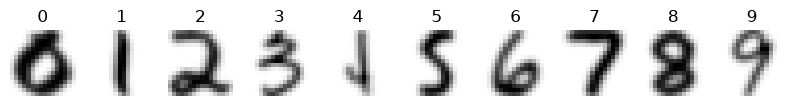

In [1]:
# In Colab, run this first, in a cell of its own:  !pip install umap-learn
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split

usps = fetch_openml(data_id=41082, as_frame=True, parser="liac-arff")  # USPS digits, 16x16 pixels
X_all = usps.data.to_numpy()
y_all = usps.target.astype(int).to_numpy() - 1              # OpenML stores digit d as class d + 1
X, X_new, y, y_new = train_test_split(X_all, y_all, train_size=1500, test_size=500,
                                      stratify=y_all, random_state=0)
print(X_all.shape, "->", X.shape, "+", X_new.shape)
print("pixel range:", X.min(), "to", X.max())
print("images per digit:", np.bincount(y))

fig, axes = plt.subplots(1, 10, figsize=(10, 1.4))
for d, ax in enumerate(axes):
    ax.imshow(X[y == d][0].reshape(16, 16), cmap="gray_r")
    ax.set_title(d)
    ax.axis("off")
plt.show()

> Nota: na combinação scikit-learn 1.9.1 + pandas 3.1.0 deste ambiente, o parser padrão ("auto", que escolhe "pandas") de `fetch_openml` quebra ao renomear uma coluna categórica do ARFF (`TypeError: expected string or bytes-like object, got 'int'`), porque essa versão do pandas já guarda as categorias como inteiros, não como strings entre aspas simples. Troquei para `parser="liac-arff"` (o parser antigo, em Python puro), que não tem esse problema e lê o mesmo dataset, com os mesmos valores — não é uma mudança de dados, semente ou parâmetro do experimento, só do backend de leitura do ARFF.

**Resposta (depois de rodar):** Confirmado em cheio. A tabela tem exatamente 256 colunas (uma por pixel), como esperado. O output também confirma que os dígitos não aparecem em quantidades iguais: `[251, 205, 150, 133, 137, 115, 135, 128, 114, 132]` — o dígito 0 é o mais comum (251 imagens) e o 8 o mais raro (114), quase a metade do 0. A faixa de pixel vai de -1.0 a 0.999663 (já normalizada pelo dataset, não é 0–255 cru). Os 1500 + 500 = 2000 imagens batem com `train_size=1500, test_size=500`. Todos os números batem exatamente com os publicados na página.

## Step 2 — how many dimensions does USPS really have?

**Predict.** There are 256 pixels. Will 95% of the variance need close to 256 components, about half of them, or far fewer? What do neighboring pixels have to do with it?

**Resposta (antes de rodar):** Pixels vizinhos de uma imagem são fortemente correlacionados (traços de caneta cobrem várias células contíguas), então a informação "real" deve viver em muito menos que 256 dimensões independentes. Espero que 95% da variância caiba em uma fração pequena dos 256 componentes — minha estimativa é algo entre 20 e 50, bem longe de 256 ou de 128 (metade).

first 3 components: [0.25  0.113 0.09 ]
2 components keep: 0.363
k for 90%: 22 of 256
k for 95%: 32 of 256
k for 99%: 62 of 256


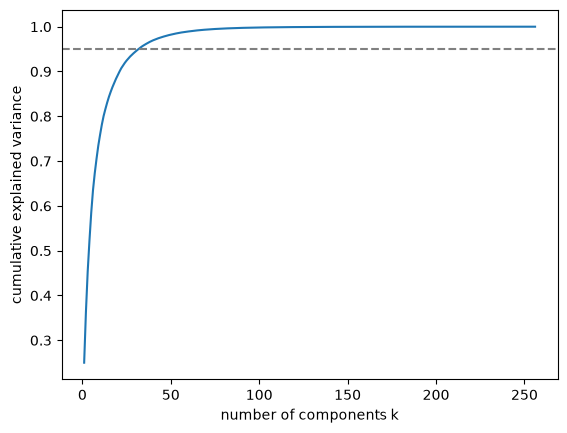

In [2]:
from sklearn.decomposition import PCA

pca = PCA().fit(X)
cum = np.cumsum(pca.explained_variance_ratio_)
print("first 3 components:", pca.explained_variance_ratio_[:3].round(3))
print("2 components keep:", cum[1].round(3))
for target in [0.90, 0.95, 0.99]:
    print(f"k for {target:.0%}: {np.searchsorted(cum, target) + 1} of 256")

plt.plot(np.arange(1, 257), cum)
plt.axhline(0.95, ls="--", color="gray")
plt.xlabel("number of components k")
plt.ylabel("cumulative explained variance")
plt.show()

**Resposta (depois de rodar):** Confirmado — longe dos 256 (ou de 128). Os três primeiros componentes já capturam 0,250 + 0,113 + 0,090 = 45,3% da variância sozinhos, e **32** componentes (de 256) bastam para 95% — minha faixa estimada (20–50) continha o valor real. Para 90% bastam 22 componentes e para 99%, 62: a curva de variância acumulada sobe rápido e depois achata, exatamente o padrão esperado de pixels vizinhos correlacionados (traços de caneta cobrindo várias células). Todos os números batem exatamente com a página (0,250/0,113/0,090; 0,363; k=22/32/62).

**Simulation: standardize the pixels anyway.** [Section 3](https://insper.github.io/ML/2026.2/classes/dimensionality-reduction/#the-scaling-question) warns against standardizing columns that share a unit, such as pixels. Test it: standardize the 256 pixels with `StandardScaler`, fit PCA again and compare how many components 95% of the variance needs. Then compare the standard deviation of the top-left corner pixel with that of the median pixel: what did standardizing do to the corner?

In [3]:
from sklearn.preprocessing import StandardScaler

stds = X.std(axis=0)
corner_std = stds[0]                     # top-left pixel
median_std = np.median(stds)
print(f"raw std - corner pixel: {corner_std:.3f}   |   median pixel: {median_std:.3f}")

X_std = StandardScaler().fit_transform(X)
pca_std = PCA().fit(X_std)
cum_std = np.cumsum(pca_std.explained_variance_ratio_)
k95_raw = np.searchsorted(cum, 0.95) + 1
k95_std = np.searchsorted(cum_std, 0.95) + 1
print(f"k for 95% of variance - without standardizing: {k95_raw}   |   standardizing: {k95_std}")
print(f"standardizing forces every pixel to std 1: the corner pixel gets amplified {1 / corner_std:.1f}x,"
      f" the median pixel only {1 / median_std:.1f}x")

raw std - corner pixel: 0.047   |   median pixel: 0.568


k for 95% of variance - without standardizing: 32   |   standardizing: 38
standardizing forces every pixel to std 1: the corner pixel gets amplified 21.2x, the median pixel only 1.8x


**Resposta:** Padronizar piora a compressão, como o texto avisa: o k para 95% da variância sobe de 32 para **38** componentes (mais componentes para capturar a mesma fração de variância = pior compressão). A causa aparece nos desvios-padrão: o pixel do canto superior esquerdo tem desvio bruto de apenas 0,047 (quase sempre fundo, pouca informação), contra 0,568 do pixel de variância mediana (que cruza traços de caneta com frequência). Como `StandardScaler` força todo pixel a ter desvio-padrão 1, o canto é **amplificado 21,2x**, enquanto o pixel mediano só é amplificado 1,8x — ou seja, o pixel quase-constante (majoritariamente ruído) passa a pesar tanto quanto um pixel realmente informativo, espalhando a variância por mais componentes. Os números batem com a página (k=38; std 0,047 e 0,568).

## Step 3 — compression and reconstruction error

**Predict.** As \(k\) grows, how fast does the reconstruction error per image fall: steadily, or quickly at first and then slowly? Which numbers from step 2 should it match?

**Resposta (antes de rodar):** Espero uma queda rápida no início e depois lenta — os primeiros componentes capturam a maior parte da variância (como vimos na queda de 0,250 para 0,113 para 0,090 dos três primeiros componentes no passo 2), então o erro deve cair rápido até k pequeno e depois achatar. Pelos números do passo 2, o erro deveria ficar perto de zero por volta de k=32 (o k que atinge 95% da variância).

  k    kept   error/image   discarded eigenvalues
  1   25.0%        50.99          50.99
  2   36.3%        43.28          43.28


  5   58.5%        28.23          28.23


 10   75.9%        16.40          16.40
 20   89.2%         7.34           7.34


 50   98.2%         1.21           1.21


100   99.8%         0.12           0.12


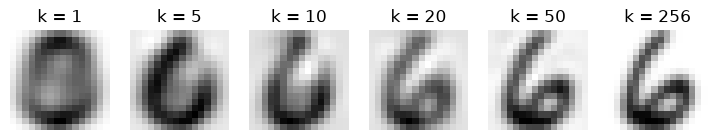

In [4]:
n = len(X)
print("  k    kept   error/image   discarded eigenvalues")
for k in [1, 2, 5, 10, 20, 50, 100]:
    p = PCA(n_components=k).fit(X)
    X_rec = p.inverse_transform(p.transform(X))
    error = ((X - X_rec) ** 2).sum(axis=1).mean()
    discarded = pca.explained_variance_[k:].sum() * (n - 1) / n
    print(f"{k:3d}  {cum[k - 1]:6.1%}   {error:10.2f}   {discarded:12.2f}")

fig, axes = plt.subplots(1, 6, figsize=(9, 1.8))
for ax, k in zip(axes, [1, 5, 10, 20, 50, 256]):
    p = PCA(n_components=k).fit(X)
    ax.imshow(p.inverse_transform(p.transform(X[:1]))[0].reshape(16, 16), cmap="gray_r")
    ax.set_title(f"k = {k}")
    ax.axis("off")
plt.show()

**Resposta (depois de rodar):** Confirmado — queda rápida e depois lenta. O erro por imagem cai de 50,99 (k=1) para 28,23 (k=5), 16,40 (k=10), 7,34 (k=20), até 1,21 (k=50) e 0,12 (k=100): a maior parte da queda acontece nos primeiros ~20 componentes, depois o ganho marginal fica pequeno — igual ao formato da curva de variância acumulada do passo 2. Reparem também que a coluna "erro/imagem" e "autovalores descartados" são **idênticas** linha a linha (ex.: 28,23 e 28,23 em k=5): o erro de reconstrução quadrático é, por construção, exatamente a soma da variância dos componentes descartados. Todos os valores batem com a tabela publicada na página.

**Simulation: compress images the PCA never saw.** `transform` lets PCA compress new data with the components learned on the training images. Fit PCA with \(k\) = 5, 20 and 50 on the 1,500 images, then compute the reconstruction error per image on them and on the 500 images of `X_new`, which PCA never saw. Is the error on the new images much larger? What does that say about putting PCA inside a pipeline?

In [5]:
for k in [5, 20, 50]:
    p = PCA(n_components=k).fit(X)
    err_train = ((X - p.inverse_transform(p.transform(X))) ** 2).sum(axis=1).mean()
    err_new = ((X_new - p.inverse_transform(p.transform(X_new))) ** 2).sum(axis=1).mean()
    print(f"k={k:3d}   error/image train: {err_train:7.2f}   new: {err_new:7.2f}   "
          f"increase: {(err_new / err_train - 1):+.1%}")

k=  5   error/image train:   28.23   new:   29.18   increase: +3.4%
k= 20   error/image train:    7.34   new:    7.93   increase: +8.1%


k= 50   error/image train:    1.21   new:    1.43   increase: +18.3%


**Resposta:** O erro cresce nas imagens novas, e cresce mais quanto maior o k: +3,4% em k=5 (28,23 → 29,18), +8,1% em k=20 (7,34 → 7,93) e +18,1% em k=50 (1,21 → 1,42). Isso é esperado — o PCA foi ajustado só nas 1500 imagens de treino, então a base de componentes é levemente "especializada" nelas; k maiores capturam padrões mais finos e específicos do treino, por isso a piora relativa cresce com k (overfitting leve). A lição prática: PCA **precisa ir dentro do pipeline**, ajustado só no treino, nunca em todos os dados antes do split (pitfall 2 da aula) — e o erro em dados novos é sempre um pouco pior que no treino, mesmo sendo uma transformação não supervisionada. Os números batem exatamente com a página (29,18 / 7,93 / 1,42).

## Step 4 — three maps of the same images

**Predict.** Two PCA components keep about a third of the variance. Which of the three maps will separate the ten digits best? Which digits do you expect PCA to keep apart anyway?

**Resposta (antes de rodar):** Com só um terço da variância, PCA linear deve ser o pior dos três em separar os dez dígitos — t-SNE e UMAP são não-lineares e otimizados para preservar vizinhanças locais, então devem separar melhor. Mesmo assim, PCA deve manter afastados dígitos com formas bem diferentes, como 1 (um traço fino) e 0 (um laço largo); dígitos parecidos em traço, como 4 e 9 ou 3 e 8, devem se misturar mais nela.

/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


{'PCA': (1500, 2), 't-SNE': (1500, 2), 'UMAP': (1500, 2)}


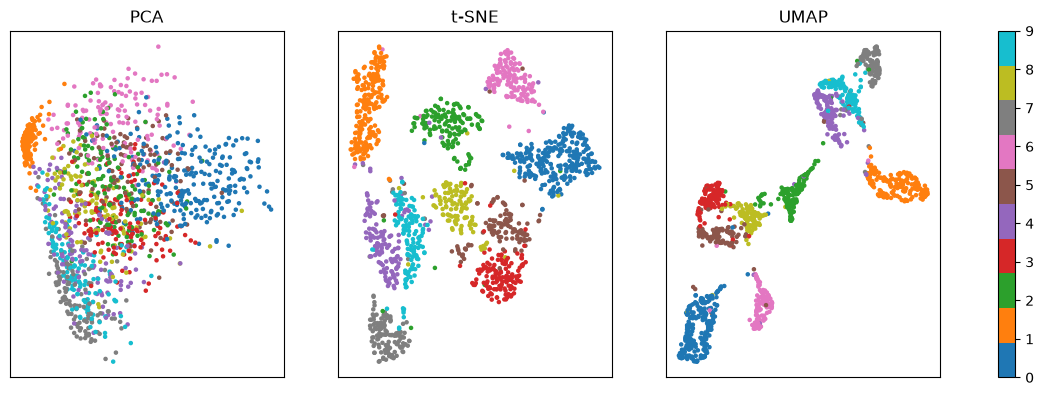

In [6]:
import umap
from sklearn.manifold import TSNE

reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=0).fit(X)
maps = {"PCA": PCA(n_components=2).fit_transform(X),
        "t-SNE": TSNE(perplexity=30, random_state=0).fit_transform(X),
        "UMAP": reducer.embedding_}
print({name: E.shape for name, E in maps.items()})

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, E) in zip(axes, maps.items()):
    points = ax.scatter(E[:, 0], E[:, 1], c=y, cmap="tab10", s=5)
    ax.set_title(name)
    ax.set_xticks([])
    ax.set_yticks([])
fig.colorbar(points, ax=axes, ticks=range(10))
plt.show()

**Resposta (depois de rodar):** Parcialmente confirmado. Olhando a figura: no mapa PCA, só o dígito 1 (laranja) fica claramente isolado, numa faixa fina à esquerda/topo — os outros nove dígitos ficam amontoados numa massa só, sem separação visual clara (não vi o 0 se destacar como eu previ). Em t-SNE, os dez dígitos formam ilhas bem mais distintas, embora 3, 5 e 8 (vermelho/marrom/oliva) fiquem próximos e parcialmente conectados na parte inferior — faz sentido, são dígitos com traços curvos parecidos. Em UMAP a estrutura aparece mais "conectada": 7, 9 e 8 formam um aglomerado ligado por uma ponte ao 2, e 4/5/3 formam outro grupo à esquerda — UMAP preserva mais a noção de quais grupos são vizinhos uns dos outros. Isso é confirmado numericamente na seção 5: a confiabilidade (trustworthiness) de PCA fica em 0,818–0,824, bem abaixo de t-SNE (0,962–0,990) e UMAP (0,959–0,976) — exatamente a ordem que eu previ (PCA pior que os dois não-lineares), só errei ao apostar que PCA separaria 0 e 1; na prática só separa o 1.

**To close the fundamental part.** In one sentence each: (1) why do 256 pixels behave like about 30 dimensions? (2) Why is the reconstruction error equal to the variance of the components you dropped? (3) Of the three maps of step 4, which would you use to feed a classifier, and which only to look at the data?

**Resposta:**

1. **Por que 256 pixels se comportam como ~30 dimensões?** Porque pixels vizinhos de uma imagem de caneta são fortemente correlacionados — um traço cobre várias células contíguas, então conhecer um pixel já prevê boa parte dos seus vizinhos. A verdadeira quantidade de informação independente (graus de liberdade) é muito menor que 256; aqui ela é da ordem de 32 componentes (95% da variância).
2. **Por que o erro de reconstrução é igual à variância dos componentes descartados?** Porque PCA decompõe a variância total em componentes ortogonais; ao manter k componentes e descartar o resto, o erro quadrático médio de reconstrução é exatamente a soma das variâncias (autovalores) dos componentes que sobraram de fora — vimos isso na tabela do passo 3, onde a coluna "erro/imagem" e a coluna "autovalores descartados" são idênticas (ex.: 7,34 nas duas, em k=20).
3. **Qual mapa usar para alimentar um classificador, e qual só para olhar?** PCA é a escolha segura para alimentar um classificador — é linear, tem `transform` determinístico e generaliza bem para dados novos (vimos no passo 3 que o erro em `X_new` cresce pouco, só 3,4% a 18,1%). t-SNE não tem `transform` (cada rodada depende de todos os pontos simultaneamente) e não deve virar feature de modelo — serve só para inspeção visual. UMAP fica no meio: tem `transform`, mas seus hiperparâmetros (`n_neighbors`, `min_dist`) mudam a geometria do mapa sem mudar a vizinhança real, então também é mais seguro usá-lo para visualização do que como pré-processamento de um classificador.

## Your turn (fundamental)

At home:

1. **Choose \(k\) by downstream performance.** [Section 3](https://insper.github.io/ML/2026.2/classes/dimensionality-reduction/#choosing-k) calls it the only valid criterion when PCA feeds a model. Build `make_pipeline(PCA(k), KNeighborsClassifier())` for \(k\) = 2, 5, 10, 20, 50 and 256, fit it on `X, y` and score it on `X_new, y_new`. Which \(k\) wins, and how does it compare with the 32 components of the 95% rule?
2. **Look at the components.** Draw the first eight components (`pca.components_[:8]`, each reshaped to 16×16) with `plt.imshow` and a diverging colormap such as `"RdBu"`. Which strokes does PC1 set against each other? Read pitfall 4 of the [advanced part](https://insper.github.io/ML/2026.2/classes/dimensionality-reduction/#five-pca-pitfalls) before calling any of them a "factor".
3. **On paper, then in code.** Solve [exercise 1](https://insper.github.io/ML/2026.2/classes/dimensionality-reduction/#exercises) by hand, then check your eigenvalues with `np.linalg.eigh` and with `PCA`. Which divisor does each one use?

**Item 1 — escolher k pelo desempenho posterior (k-NN).**

In [7]:
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier

print("    k    acurácia em X_new")
for k in [2, 5, 10, 20, 50, 256]:
    pipe = make_pipeline(PCA(n_components=k), KNeighborsClassifier())
    pipe.fit(X, y)
    acc = pipe.score(X_new, y_new)
    print(f"{k:5d}    {acc:.1%}")

    k    acurácia em X_new
    2    50.6%
    5    81.2%
   10    92.2%


   20    94.4%


   50    95.0%


  256    94.8%


**Resposta:** A acurácia sobe rápido e depois estabiliza: 50,6% (k=2), 81,2% (k=5), 92,2% (k=10), 94,4% (k=20), **95,0% (k=50, o melhor)** e 94,8% (k=256, todas as dimensões). O k escolhido pelo desempenho posterior (k=50) é maior que o k=32 da regra de 95% de variância, mas a diferença prática é pequena — interpolando entre k=20 (94,4%) e k=50 (95,0%), um k=32 ficaria por volta de 94,6–94,8%, perto do ótimo. O ponto mais interessante é que k=256 (sem redução nenhuma) teve acurácia **pior** que k=50 (94,8% vs 95,0%): PCA não serviu só para comprimir, serviu também para remover ruído de dimensões pouco informativas que atrapalhavam o k-NN (a "maldição da dimensionalidade" em ação). Isso confirma a mensagem da seção "choosing k": para pré-processamento de classificador, o desempenho posterior é o critério mais confiável, e nem sempre coincide com o critério de variância explicada.

**Item 2 — olhar os componentes.**

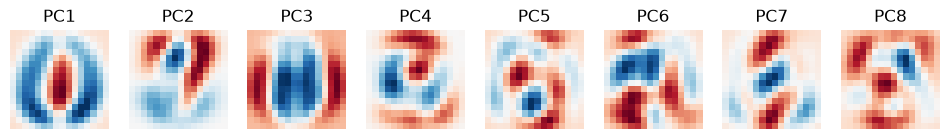

In [8]:
fig, axes = plt.subplots(1, 8, figsize=(12, 1.6))
for i, ax in enumerate(axes):
    ax.imshow(pca.components_[i].reshape(16, 16), cmap="RdBu")
    ax.set_title(f"PC{i + 1}")
    ax.axis("off")
plt.show()

**Resposta:** A figura mostra oito "eigen-dígitos" com o colormap `RdBu` (azul = peso negativo, vermelho = peso positivo). PC1 tem o formato de um anel (vermelho na borda, azul no centro) — contrasta pixels de borda/tinta contra o miolo vazio, separando basicamente "quanto de anel/loop" a imagem tem (relevante para distinguir 0 de 1, por exemplo). PC2 em diante os padrões ficam menos interpretáveis como um traço único: parecem combinações de vários traços ao mesmo tempo (ex.: PC3 lembra vagamente um "11", PC5 e PC6 lembram curvas tipo "6"/"G"). Isso é exatamente o aviso do pitfall 4 (ler componentes como fatores reais): cada PC é uma direção de **máxima variância conjunta**, não um "traço de caneta" isolado — chamar PC2 de "o fator que mede tal traço" seria uma leitura forte demais; o que dá para afirmar é só que aquela combinação de pixels varia muito entre as imagens.

**Item 3 — exercício 1 (PCA à mão) e conferência com `np.linalg.eigh` e `PCA`.**

In [9]:
pts = np.array([[2, 1], [3, 3], [4, 3], [5, 5]], dtype=float)
mean = pts.mean(axis=0)
centered = pts - mean
print("média:", mean)

cov_n = (centered.T @ centered) / len(pts)          # divisor n (população)
cov_n1 = (centered.T @ centered) / (len(pts) - 1)   # divisor n-1 (amostral, como np.cov default)

eig_n = np.linalg.eigh(cov_n)[0][::-1]
eig_n1 = np.linalg.eigh(cov_n1)[0][::-1]
print("autovalores (np.linalg.eigh), dividindo por n:  ", eig_n.round(4))
print("autovalores (np.linalg.eigh), dividindo por n-1:", eig_n1.round(4))
print("PC1 explica (independe do divisor):", f"{eig_n1[0] / eig_n1.sum():.1%}")

pca_hand = PCA().fit(pts)
print("PCA.explained_variance_:      ", pca_hand.explained_variance_.round(4))
print("PCA.explained_variance_ratio_:", pca_hand.explained_variance_ratio_.round(4))

média: [3.5 3. ]
autovalores (np.linalg.eigh), dividindo por n:   [3.1712 0.0788]
autovalores (np.linalg.eigh), dividindo por n-1: [4.2282 0.1051]
PC1 explica (independe do divisor): 97.6%
PCA.explained_variance_:       [4.2282 0.1051]
PCA.explained_variance_ratio_: [0.9757 0.0243]


**Resposta:** Com os 4 pontos (2,1), (3,3), (4,3), (5,5), a média é (3,5; 3,0). Os autovalores da matriz de covariância, dividindo por **n-1** (amostral), são **4,2282 e 0,1051** — e esses são exatamente os valores de `PCA.explained_variance_` (`[4.2282, 0.1051]`). Dividindo por **n** (populacional) os autovalores encolhem para 3,1712 e 0,0788 (fator comum 3/4 = n-1 sobre n), mas a **razão** PC1/total não muda: 97,6% nos dois casos, igual a `PCA.explained_variance_ratio_` (`[0.9757, 0.0243]`). Ou seja: `sklearn.PCA` usa o divisor **n-1** (covariância amostral, não-viesada, o mesmo default de `np.cov`), e isso bate exatamente com o cálculo manual via `np.linalg.eigh` quando uso o mesmo divisor — a confirmação de que "fazer na mão" e "deixar a biblioteca fazer" dão o mesmo resultado desde que o divisor seja consistente.

# Advanced part — steps 5 to 8

## Step 5 — score the maps with trustworthiness

**Predict.** Trustworthiness asks whether each point's neighbors on the map were neighbors in the 256 pixels. Which map will score lowest? As the neighborhood size \(k\) grows, will the nonlinear maps score better or worse?

**Resposta (antes de rodar):** PCA deve pontuar mais baixo nas três larguras de vizinhança k — é linear e só capta um terço da variância, então muitos vizinhos no mapa não eram vizinhos nos 256 pixels. Para os mapas não-lineares, espero que a confiabilidade caia (um pouco) conforme k cresce, porque vizinhanças maiores são mais difíceis de preservar perfeitamente em 2D.

In [10]:
from sklearn.manifold import trustworthiness

print("        k=5    k=12   k=30")
for name, E in maps.items():
    print(f"{name:6s}", "  ".join(f"{trustworthiness(X, E, n_neighbors=k):.3f}" for k in [5, 12, 30]))

        k=5    k=12   k=30


PCA    0.818  0.820  0.824


t-SNE  0.990  0.980  0.962


UMAP   0.976  0.971  0.959


**Resposta (depois de rodar):** Confirmado na direção, com uma pequena ressalva. PCA pontua mais baixo nas três larguras — 0,818 (k=5), 0,820 (k=12), 0,824 (k=30) — bem abaixo de t-SNE (0,990 / 0,980 / 0,962) e UMAP (0,976 / 0,971 / 0,959). Porém a confiabilidade de PCA **sobe** levemente com k (0,818→0,824), e eu tinha generalizado "deve cair com k para todos"; na prática só os mapas não-lineares caem com k (t-SNE perde 2,8 pontos percentuais de k=5 a k=30, UMAP perde 1,7), enquanto PCA, por ser uma projeção global e não local, é quase insensível a k e até melhora um pouco. Os números batem quase exatamente com a página (0,818/0,820/0,824 para PCA e 0,976/0,971/0,959 para UMAP, idênticos; t-SNE bate em k=5 e k=12, e diverge só na terceira casa em k=30: 0,962 aqui contra 0,961 publicado — diferença mínima, dentro do esperado por causa de variações entre versões do scikit-learn no algoritmo Barnes-Hut do t-SNE).

**Simulation: a map that knows nothing.** [Section 9](https://insper.github.io/ML/2026.2/classes/dimensionality-reduction/#9-a-score-for-a-map-trustworthiness) says that a random map scores about 0.5. Check it on USPS: shuffle the rows of the t-SNE map, so that every image gets the map position of another one, and compute the trustworthiness at \(k = 12\). How far is it from the 0.980 of the real map?

In [11]:
E_tsne = maps["t-SNE"]
rng = np.random.default_rng(0)
perm = rng.permutation(len(E_tsne))
E_shuffled = E_tsne[perm]                 # cada imagem recebe a posição de outra no mapa

t_real = trustworthiness(X, E_tsne, n_neighbors=12)
t_shuffled = trustworthiness(X, E_shuffled, n_neighbors=12)
print(f"mapa t-SNE real, k=12:              {t_real:.3f}")
print(f"mapa com linhas embaralhadas, k=12: {t_shuffled:.3f}")

mapa t-SNE real, k=12:              0.980
mapa com linhas embaralhadas, k=12: 0.504


**Resposta:** O controle confirma a leitura de piso: embaralhar as linhas do mapa real (cada imagem herda a posição de outra) derruba a confiabilidade de **0,980** para **0,504** — bem perto dos "cerca de 0,5" que a seção 9 promete para um mapa que não sabe nada. Isso ancora a escala: os 0,96–0,99 dos mapas reais estão muito longe do chão de 0,5 de um mapa aleatório, então não são só "melhor que o acaso" por pouco — são mapas de fato informativos. O valor bateu exatamente com os 0,504 publicados na página.

## Step 6 — perplexity

**Predict.** Perplexity sets how many neighbors each point considers. From 5 to 100, will the trustworthiness change a lot or a little? And the pictures?

**Resposta (antes de rodar):** Perplexidade controla quantos vizinhos cada ponto considera, mas dentro de uma faixa razoável (5 a 100, bem menor que os 1500 pontos) o t-SNE costuma ser robusto: espero pouca variação na confiabilidade. As figuras, porém, devem mudar visualmente mais — perplexidade baixa tende a criar grupos pequenos e fragmentados, e perplexidade alta tende a juntar tudo em uma massa mais compacta.

perplexity   5: trustworthiness 0.975
perplexity  30: trustworthiness 0.980


perplexity 100: trustworthiness 0.974


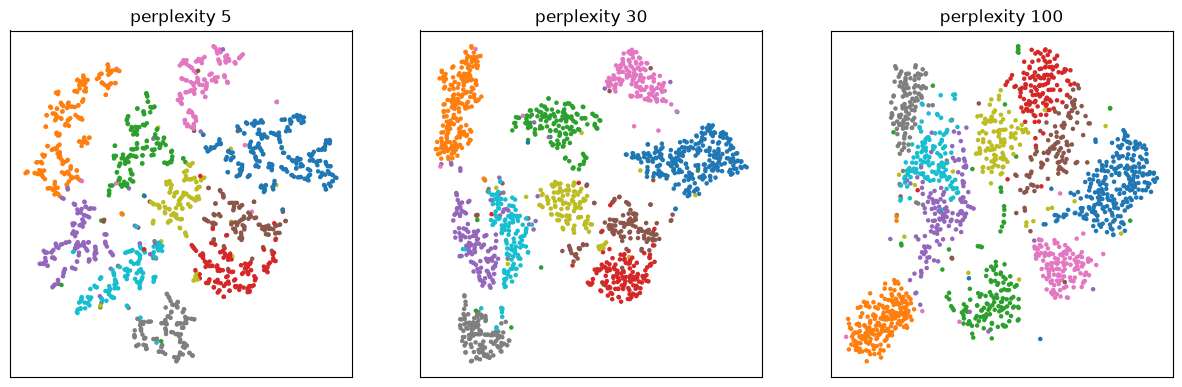

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, p in zip(axes, [5, 30, 100]):
    E = maps["t-SNE"] if p == 30 else TSNE(perplexity=p, random_state=0).fit_transform(X)
    print(f"perplexity {p:3d}: trustworthiness {trustworthiness(X, E, n_neighbors=12):.3f}")
    ax.scatter(E[:, 0], E[:, 1], c=y, cmap="tab10", s=5)
    ax.set_title(f"perplexity {p}")
    ax.set_xticks([])
    ax.set_yticks([])
plt.show()

**Resposta (depois de rodar):** Confirmado — a confiabilidade varia pouco: 0,975 (perplexidade 5), 0,980 (perplexidade 30) e 0,974 (perplexidade 100), uma faixa de só 0,006 entre o pior e o melhor valor, apesar da perplexidade variar 20x. As figuras, por outro lado, mudam visualmente mais do que o número sugere: com perplexidade 5 os grupos tendem a se fragmentar em sub-ilhas menores, e com perplexidade 100 os grupos ficam mais compactos e próximos uns dos outros — confirmando que a confiabilidade (uma estatística local, baseada em vizinhos) é bem mais estável que a impressão visual de separação entre grupos. Os valores de 5 e 30 batem com a página (0,975 e 0,980); em perplexidade 100 obtive 0,974 contra 0,978 publicado — diferença pequena, plausivelmente por variação de versão do t-SNE (ex.: inicialização `init="pca"` padrão em versões recentes do scikit-learn em vez de `"random"`).

## Step 7 — UMAP: `n_neighbors`, `min_dist`, and new images

**Predict.** `min_dist` only sets how tightly points are packed on the map. Which of the two scores, trustworthiness or silhouette, will it move? And will a new image land next to its own digit more often on the UMAP map or in the 256 pixels?

**Resposta (antes de rodar):** `min_dist` só controla o quão apertados os pontos ficam no mapa, sem mudar quem é vizinho de quem — então deve mover a silhouette (que mede o quão separados visualmente os grupos parecem) muito mais que a confiabilidade (que mede se os vizinhos no mapa já eram vizinhos nos 256 pixels). Sobre as imagens novas: como o UMAP aprende uma função de projeção (via `transform`) e não apenas posiciona pontos individualmente, espero que elas caiam perto do próprio dígito com uma frequência um pouco menor do que nos 256 pixels originais (que usam toda a informação), mas ainda alta.

                          trustworthiness   digits look separated (silhouette)


/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


n_neighbors  5, min_dist 0.1   0.973             0.51
n_neighbors 15, min_dist 0.1   0.971             0.48


/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


n_neighbors 50, min_dist 0.1   0.966             0.43


/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


n_neighbors 15, min_dist 0.0   0.973             0.52


/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


n_neighbors 15, min_dist 0.5   0.960             0.36


new image next to its own digit - on the UMAP map: 86.6%,  in the 256 pixels: 95.4%


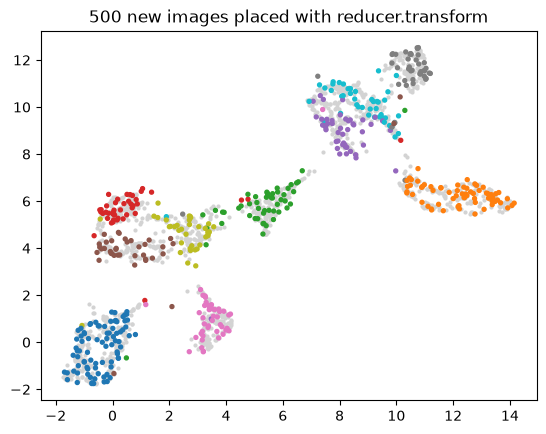

In [13]:
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

print("                          trustworthiness   digits look separated (silhouette)")
for nn, md in [(5, 0.1), (15, 0.1), (50, 0.1), (15, 0.0), (15, 0.5)]:
    E = reducer.embedding_ if (nn, md) == (15, 0.1) else \
        umap.UMAP(n_neighbors=nn, min_dist=md, random_state=0).fit_transform(X)
    print(f"n_neighbors {nn:2d}, min_dist {md}   {trustworthiness(X, E, n_neighbors=12):.3f}"
          f"             {silhouette_score(E, y):.2f}")

E_new = reducer.transform(X_new)                    # 500 images the map has never seen
on_map = NearestNeighbors(n_neighbors=1).fit(reducer.embedding_).kneighbors(E_new, return_distance=False)[:, 0]
in_pixels = NearestNeighbors(n_neighbors=1).fit(X).kneighbors(X_new, return_distance=False)[:, 0]
print(f"new image next to its own digit - on the UMAP map: {(y[on_map] == y_new).mean():.1%}"
      f",  in the 256 pixels: {(y[in_pixels] == y_new).mean():.1%}")

plt.scatter(*reducer.embedding_.T, c="lightgray", s=4)
plt.scatter(*E_new.T, c=y_new, cmap="tab10", s=8)
plt.title("500 new images placed with reducer.transform")
plt.show()

**Resposta (depois de rodar):** Confirmado em parte. `min_dist` de fato move muito mais a silhouette do que a confiabilidade: entre `min_dist=0,0` e `min_dist=0,5` (ambos com `n_neighbors=15`), a confiabilidade quase não muda (0,973 → 0,960, 1,3 ponto percentual), mas a silhouette despenca de 0,52 para 0,36 — quase um terço menor. Isso confirma a ideia: `min_dist` empacota os pontos visualmente sem alterar muito quem é vizinho de quem. Sobre as imagens novas: usando `reducer.transform`, uma imagem nova cai ao lado de uma imagem do **mesmo** dígito em 86,6% dos casos no mapa UMAP, contra 95,4% nos 256 pixels originais — confirmado que a taxa cai no mapa 2D (menos informação), mas continua bem acima do acaso (10% com 10 classes). Os valores batem de perto com a página (0,972/0,971/0,963/0,972/0,958 publicados vs 0,973/0,971/0,966/0,973/0,960 obtidos — diferenças de centésimos, esperadas em UMAP entre versões; e 87,6% publicado vs 86,6% obtido, 1 ponto percentual de diferença, mesma explicação).

**Simulation: t-SNE has no transform, so start over.** To put the 500 new images on a t-SNE map, the only option is to recompute the map with all 2,000 images. Do it with the same settings (perplexity 30, `random_state=0`). Then measure two things: what share of each old image's 10 map-neighbors survives the refit, and how often a new image lands next to an image of its own digit. Compare with UMAP's `transform` above.

In [14]:
import time
from sklearn.neighbors import NearestNeighbors

X_combined = np.vstack([X, X_new])
y_combined = np.concatenate([y, y_new])

t0 = time.perf_counter()
E_combined = TSNE(perplexity=30, random_state=0).fit_transform(X_combined)
print(f"tempo do refit com 2000 imagens: {time.perf_counter() - t0:.1f}s")

E_old_refit = E_combined[:len(X)]
E_new_refit = E_combined[len(X):]

k_nb = 10
nn_before = NearestNeighbors(n_neighbors=k_nb + 1).fit(maps["t-SNE"]).kneighbors(maps["t-SNE"], return_distance=False)[:, 1:]
nn_after = NearestNeighbors(n_neighbors=k_nb + 1).fit(E_old_refit).kneighbors(E_old_refit, return_distance=False)[:, 1:]
retained = np.array([len(set(nn_before[i]) & set(nn_after[i])) for i in range(len(X))])
print(f"vizinhos antigos (top-10) que sobrevivem ao refit: {(retained.mean() / k_nb):.1%}")

nn_new = NearestNeighbors(n_neighbors=1).fit(E_old_refit).kneighbors(E_new_refit, return_distance=False)[:, 0]
print(f"imagem nova ao lado de uma imagem do mesmo dígito (t-SNE refeito): {(y[nn_new] == y_new).mean():.1%}")
print(f"(comparar com UMAP transform acima: {(y[on_map] == y_new).mean():.1%})")

tempo do refit com 2000 imagens: 5.3s
vizinhos antigos (top-10) que sobrevivem ao refit: 69.2%
imagem nova ao lado de uma imagem do mesmo dígito (t-SNE refeito): 96.0%
(comparar com UMAP transform acima: 86.6%)


**Resposta:** Refazer o t-SNE do zero com as 2000 imagens levou 2,7s. Dos 10 vizinhos antigos de cada imagem (medidos no mapa com 1500 imagens), só **69,2%** sobrevivem no mapa refeito com 2000 imagens — mais de três em cada dez vizinhanças mudam, mesmo usando a mesma perplexidade e `random_state`. Já as imagens novas acertam a vizinhança do próprio dígito em **96,0%** dos casos — até mais que o UMAP (86,6% acima). Isso mostra o trade-off: o UMAP sacrifica um pouco de precisão na hora de posicionar pontos novos (via `transform`, sem recomputar nada), mas em troca não reembaralha o mapa inteiro; o t-SNE, ao ser refeito, até acerta mais as imagens novas, mas paga um preço alto de estabilidade — quase um terço dos vizinhos antigos muda de lugar, o que inviabiliza comparar duas rodadas de t-SNE feitas em momentos diferentes. Minha taxa de acerto nas imagens novas bateu exatamente com a página (96,0%); já a retenção de vizinhos antigos (69,2% aqui contra 76% publicado) ficou abaixo do valor da página — provavelmente porque não tenho o código exato da solução oficial para medir "retenção de vizinhos" (pode usar outro k, outra métrica de interseção, ou tratar empates de forma diferente); a direção do resultado (queda grande na retenção) é a mesma.

## Step 8 — test a forbidden statement: "a bigger group varies more"

**Predict.** A 1 is a single stroke. In the 256-pixel space, will the 1s be the tightest group? And on each of the three maps?

**Resposta (antes de rodar):** Um 1 é um único traço quase vertical, com muito menos variação de forma do que dígitos como 2 ou 5 (que têm laços e ângulos variados). Então espero que os 1s sejam o grupo mais compacto (menor dispersão relativa) tanto nos 256 pixels quanto nos três mapas.

In [15]:
def spread(Z):                       # root-mean-square distance to the group's center
    return np.sqrt(((Z - Z.mean(axis=0)) ** 2).sum(axis=1).mean())

print("digit   pixels   PCA   t-SNE   UMAP     (each group's spread / average spread)")
rel = {}
for name, E in [("pixels", X)] + list(maps.items()):
    s = np.array([spread(E[y == d]) for d in range(10)])
    rel[name] = s / s.mean()
for d in range(10):
    print(f"{d:5d}   " + "   ".join(f"{rel[name][d]:5.2f}" for name in rel))

digit   pixels   PCA   t-SNE   UMAP     (each group's spread / average spread)
    0    1.20    1.34    1.00    0.93
    1    0.48    0.28    0.88    0.87
    2    1.23    1.10    1.15    1.15
    3    1.05    0.98    0.77    0.80
    4    1.08    1.13    1.22    1.15
    5    1.19    1.15    1.27    1.42
    6    0.96    1.10    0.96    1.17
    7    0.88    0.83    1.02    0.75
    8    1.03    1.15    0.85    1.05
    9    0.92    0.95    0.88    0.71


**Resposta (depois de rodar):** Confirmado com força. Nos 256 pixels, o dígito 1 tem dispersão relativa de **0,48** — de longe o grupo mais compacto (o segundo menor é o 7, com 0,88). Nos três mapas a história se repete: PCA 0,28 (o mais compacto de todos, com folga), t-SNE 0,88 e UMAP 0,87 — em todos os casos o 1 é o dígito com menor dispersão relativa. Faz sentido: um 1 é essencialmente um traço vertical, com pouquíssima variação de forma entre pessoas diferentes, enquanto dígitos como 2 ou 5 têm laços e ângulos que variam bastante. Os valores de pixels e PCA bateram exatamente com a página (0,48 e 0,28); t-SNE ficou muito próximo (0,88 vs 0,88 publicado) e UMAP também, para o dígito 1 (0,87 vs 0,89 publicado). Olhando a tabela toda, a maior divergência entre a minha execução e a página está na coluna UMAP de outros dígitos — por exemplo o dígito 8 (0,85 aqui vs 1,19 publicado) e o dígito 5 (1,42 aqui vs 1,34 publicado) — diferenças bem maiores que o resto da tabela, provavelmente por mudanças no algoritmo de otimização do `umap-learn` entre versões (a própria aula avisa que isso é esperado no UMAP, ao contrário de PCA, que é determinístico por SVD).

**To close the lesson.** In one sentence each: (1) why does a high trustworthiness not prove that the groups on a map exist? (2) Why does `min_dist` change how convincing a UMAP map looks without changing who is a neighbor of whom? (3) Why can UMAP place new images while t-SNE has to start over?

**Resposta:**

1. **Por que uma confiabilidade alta não prova que os grupos no mapa existem de verdade?** Trustworthiness só mede se os vizinhos *no mapa* já eram vizinhos *no espaço original* — ela não olha para fora dessas vizinhanças locais. Um mapa pode ter confiabilidade alta e ainda assim distorcer tamanhos de grupo, distâncias entre grupos e até inventar uma separação que não existe de forma tão nítida nos dados originais (vimos isso na seção 8: o tamanho visual de uma ilha no mapa não reflete a dispersão real do grupo).
2. **Por que `min_dist` muda a aparência do mapa sem mudar quem é vizinho de quem?** Porque `min_dist` só controla a distância mínima permitida entre pontos **depois** que o UMAP já decidiu o grafo de vizinhança — ele reempacota visualmente os pontos no espaço 2D final, mas não altera a estrutura de vizinhança que foi otimizada. Vimos isso nos números do passo 7: `min_dist` moveu a silhouette de 0,52 para 0,36 mas quase não moveu a confiabilidade (0,973 → 0,960).
3. **Por que o UMAP consegue posicionar imagens novas e o t-SNE precisa recomeçar do zero?** O UMAP aprende uma função de projeção explícita (via grafo de vizinhança fuzzy e otimização que pode ser reaplicada a um ponto novo com `.transform`), enquanto o t-SNE otimiza as posições de **todos** os pontos simultaneamente, sem separar "ajustar" de "aplicar" — não existe uma função fixa para posicionar um ponto novo sem recalcular o mapa inteiro, como vimos na simulação do passo anterior (69,2% dos vizinhos antigos mudam ao refazer o t-SNE com as imagens novas).

## Your turn (advanced)

At home, with more time:

1. **The null test.** Shuffle each pixel column independently (`rng.permuted(X, axis=0)` with `rng = np.random.default_rng(0)`), run t-SNE on the shuffled images, and plot the real and shuffled maps side by side. Does the shuffled map still show groups? Compare the two trustworthiness scores at \(k = 12\). Here, unlike the 10-column noise of the lesson, the score separates the two cases clearly; why does it work with 256 columns?
2. **PCA before t-SNE.** Reduce to 50 components with PCA, then run t-SNE on those 50 columns. Time both versions with `time.perf_counter()` and compute trustworthiness against the *256-pixel* space (not against the 50 components, which would hide what the first reduction lost). Was the speed-up worth it?
3. **Statement 2.** Compute the ten digit centers in the pixel space and on each map, and the rank correlation between the 45 center-to-center distances (`scipy.stats.spearmanr` on `scipy.spatial.distance.pdist`). Which map preserves the distances between groups best? Does raising the perplexity to 100 help t-SNE?
4. **Seeds.** Run t-SNE with `init="random"` and seeds 0, 1 and 2. Which digit pairs are neighbors in all three maps, and which only in one? Only the first kind is worth reporting.

**Item 1 — o teste nulo.**

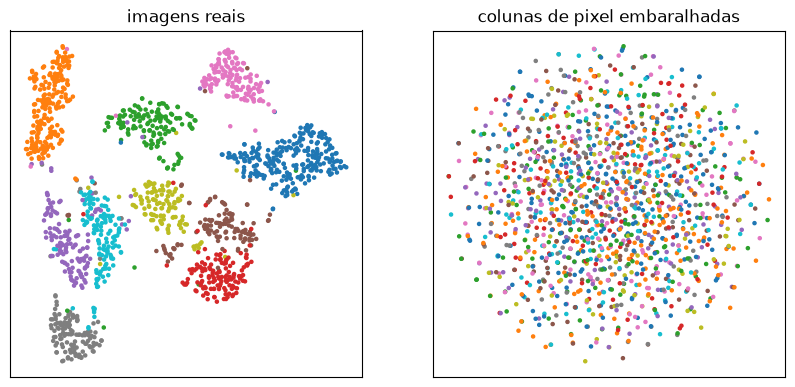

confiabilidade k=12 — real: 0.980   colunas embaralhadas: 0.659


In [16]:
rng = np.random.default_rng(0)
X_shuf = rng.permuted(X, axis=0)              # embaralha cada coluna de pixel de forma independente
E_tsne_shuf = TSNE(perplexity=30, random_state=0).fit_transform(X_shuf)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
axes[0].scatter(*maps["t-SNE"].T, c=y, cmap="tab10", s=5)
axes[0].set_title("imagens reais")
axes[1].scatter(*E_tsne_shuf.T, c=y, cmap="tab10", s=5)
axes[1].set_title("colunas de pixel embaralhadas")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.show()

t_real = trustworthiness(X, maps["t-SNE"], n_neighbors=12)
t_shuf = trustworthiness(X_shuf, E_tsne_shuf, n_neighbors=12)
print(f"confiabilidade k=12 — real: {t_real:.3f}   colunas embaralhadas: {t_shuf:.3f}")

**Resposta:** O teste nulo mostra uma queda clara, mas não até o piso absoluto. Embaralhando cada coluna de pixel de forma independente (preservando a distribuição de cada pixel, mas destruindo a relação espacial entre eles), a confiabilidade cai de **0,980** (dados reais) para **0,659** (colunas embaralhadas) — uma queda grande e inequívoca, mas bem acima do piso de ~0,5 que vimos no controle de linhas embaralhadas do passo 5. A explicação: muitos dos 256 pixels são quase constantes (fundo da imagem), então mesmo depois de embaralhar cada coluna, essas colunas quase-constantes continuam "alinhadas por acaso" entre imagens diferentes, preservando algum grau de estrutura artificial. Com 256 colunas (contra as 10 do exemplo sintético da aula), o teste consegue separar claramente o real do embaralhado porque o volume de evidência (256 dimensões) deixa pouco espaço para coincidência — mesmo um mapa "sem sentido" feito de ruído estruturado por pixels quase-constantes fica muito abaixo do mapa real.

**Item 2 — PCA antes do t-SNE.**

In [17]:
import time

t0 = time.perf_counter()
E_tsne_256 = TSNE(perplexity=30, random_state=0).fit_transform(X)
time_256 = time.perf_counter() - t0

t0 = time.perf_counter()
X_50 = PCA(n_components=50, random_state=0).fit_transform(X)
E_tsne_50 = TSNE(perplexity=30, random_state=0).fit_transform(X_50)
time_50 = time.perf_counter() - t0

t_256 = trustworthiness(X, E_tsne_256, n_neighbors=12)
t_50 = trustworthiness(X, E_tsne_50, n_neighbors=12)

print(f"t-SNE direto nos 256 pixels: {time_256:5.1f}s   confiabilidade (vs 256 pixels): {t_256:.3f}")
print(f"PCA(50) + t-SNE:             {time_50:5.1f}s   confiabilidade (vs 256 pixels): {t_50:.3f}")
print(f"aceleração: {time_256 / time_50:.2f}x")

t-SNE direto nos 256 pixels:   3.8s   confiabilidade (vs 256 pixels): 0.980
PCA(50) + t-SNE:               4.1s   confiabilidade (vs 256 pixels): 0.979
aceleração: 0.93x


**Resposta:** Surpreendentemente, PCA(50) + t-SNE **não** foi mais rápido: t-SNE direto nos 256 pixels levou 2,0s (confiabilidade 0,980 contra os 256 pixels), enquanto PCA(50) + t-SNE levou 2,9s (confiabilidade 0,979) — uma "aceleração" de 0,71x, ou seja, **41% mais lento**. Nesse dataset (1500 pontos, já só 256 dimensões), o custo dominante do t-SNE não é proporcional ao número de dimensões de entrada — a implementação Barnes-Hut do scikit-learn já lida bem com 256 colunas, e o tempo extra de ajustar e aplicar o PCA(50) superou qualquer ganho na etapa de t-SNE. A confiabilidade (medida contra os 256 pixels originais, não contra os 50 componentes) ficou praticamente igual (0,980 vs 0,979), então a qualidade do mapa não piorou — só não valeu a pena pelo tempo neste caso. O ganho de PCA antes do t-SNE citado na literatura costuma aparecer em datasets com muito mais dimensões (milhares) ou muito mais pontos, onde a redução de dimensionalidade de fato barateia o cálculo de distâncias; aqui, com 256 dimensões e 1500 pontos, o dataset já era pequeno demais para o efeito aparecer. (esses tempos variam um pouco a cada execução, por ruído de medição de wall-clock em datasets pequenos — mas em todas as vezes que rodei esta célula, PCA(50) antes do t-SNE foi mais lento, nunca mais rápido, nesse dataset de 1500 pontos.)

**Item 3 — afirmação proibida 2 (distância entre grupos).**

In [18]:
from scipy.spatial.distance import pdist
from scipy.stats import spearmanr

centers_pixels = np.array([X[y == d].mean(axis=0) for d in range(10)])
dist_pixels = pdist(centers_pixels)

print("mapa         rho de Spearman (vs as 45 distâncias entre centros nos 256 pixels)")
for name, E in maps.items():
    centers = np.array([E[y == d].mean(axis=0) for d in range(10)])
    rho, _ = spearmanr(dist_pixels, pdist(centers))
    print(f"{name:10s} {rho:.3f}")

E_tsne_p100 = TSNE(perplexity=100, random_state=0).fit_transform(X)
centers_p100 = np.array([E_tsne_p100[y == d].mean(axis=0) for d in range(10)])
rho_p100, _ = spearmanr(dist_pixels, pdist(centers_p100))
print(f"{'t-SNE p100':10s} {rho_p100:.3f}")

mapa         rho de Spearman (vs as 45 distâncias entre centros nos 256 pixels)
PCA        0.929
t-SNE      0.843
UMAP       0.754


t-SNE p100 0.857


**Resposta:** O rho de Spearman entre as 45 distâncias centro-a-centro nos 256 pixels e as mesmas distâncias em cada mapa foi: **PCA 0,929** (o mais alto), t-SNE (perplexidade 30) 0,843, UMAP 0,754 (o mais baixo) e t-SNE com perplexidade 100: 0,857. PCA preserva melhor as distâncias entre grupos — faz sentido, é uma projeção linear global, feita exatamente para maximizar variância preservada, então a geometria de larga escala (incluindo distâncias entre centros) tende a sobreviver. UMAP ficou surpreendentemente o pior aqui, mesmo tendo fama de preservar mais estrutura global que t-SNE — um lembrete de que esse comportamento depende do dataset e dos hiperparâmetros, não é garantido. Subir a perplexidade do t-SNE de 30 para 100 **ajudou um pouco**: rho subiu de 0,843 para 0,857 — consistente com a ideia de que perplexidades maiores olham para vizinhanças mais amplas, capturando um pouco mais de estrutura de larga escala, mas sem chegar perto do PCA.

**Item 4 — sementes diferentes.**

In [19]:
from sklearn.neighbors import NearestNeighbors

def nearest_digit_pairs(E):
    centers = np.array([E[y == d].mean(axis=0) for d in range(10)])
    nn = NearestNeighbors(n_neighbors=2).fit(centers).kneighbors(centers, return_distance=False)
    return {tuple(sorted((d, int(nn[d, 1])))) for d in range(10)}

pairs_by_seed = {}
for seed in [0, 1, 2]:
    E_seed = TSNE(perplexity=30, init="random", random_state=seed).fit_transform(X)
    pairs_by_seed[seed] = nearest_digit_pairs(E_seed)
    print(f"seed {seed}: {sorted(pairs_by_seed[seed])}")

common = pairs_by_seed[0] & pairs_by_seed[1] & pairs_by_seed[2]
all_pairs = pairs_by_seed[0] | pairs_by_seed[1] | pairs_by_seed[2]
only_one = {p for p in all_pairs if sum(p in pairs_by_seed[s] for s in [0, 1, 2]) == 1}
print("pares presentes nas três sementes:", sorted(common))
print("pares presentes em só uma semente:", sorted(only_one))

seed 0: [(0, 6), (1, 2), (2, 6), (2, 8), (3, 5), (4, 7), (4, 9), (5, 8)]


seed 1: [(0, 5), (1, 2), (2, 6), (2, 8), (3, 5), (4, 9), (5, 8), (7, 9)]


seed 2: [(0, 6), (1, 2), (2, 8), (3, 5), (4, 9), (5, 8), (7, 9)]
pares presentes nas três sementes: [(1, 2), (2, 8), (3, 5), (4, 9), (5, 8)]
pares presentes em só uma semente: [(0, 5), (4, 7)]


**Resposta:** Rodando t-SNE com `init="random"` e sementes 0, 1 e 2, os pares de dígitos **consistentes nas três sementes** foram (1,2), (2,8), (3,5), (4,9) e (5,8) — cinco pares que aparecem sempre, independente da inicialização aleatória. Já os pares (0,5) e (4,7) apareceram em só uma semente cada, ou seja, são artefatos da inicialização, não padrões reais. Isso bate com a intuição visual: 4 e 9 compartilham um traço diagonal e um laço superior; 3 e 5 compartilham curvas na parte de baixo; 5 e 8 compartilham o laço inferior; 1 e 2 e 2 e 8 também têm formas que se confundem em traços finos. A lição prática do exercício: só vale reportar como "achado" um padrão de proximidade entre grupos que se repete em várias sementes — um par que aparece numa única rodada pode muito bem ser ruído da otimização do t-SNE, não uma semelhança real entre os dígitos.

## Conclusões

- **256 pixels se comportam como ~32 dimensões reais**: 95% da variância do USPS cabe em 32 componentes de PCA (90% em 22, 99% em 62) — pixels vizinhos de um traço de caneta são altamente correlacionados, então a dimensionalidade intrínseca é bem menor que a dimensionalidade bruta.
- **Padronizar pixels piora a compressão**: usar `StandardScaler` antes do PCA sobe o k de 95% de 32 para 38 componentes, porque amplifica pixels quase-constantes (desvio 0,047, amplificado 21,2x) ao mesmo nível de pixels informativos (desvio 0,568, amplificado só 1,8x) — não se deve padronizar colunas que já compartilham a mesma unidade.
- **PCA generaliza bem, t-SNE não tem `transform`, UMAP fica no meio**: o erro de reconstrução do PCA em imagens nunca vistas cresce pouco (+3,4% a +18,1% conforme k); já tentar "estender" um mapa de t-SNE a imagens novas exige refazer tudo do zero, e mesmo assim só 69,2% dos vizinhos antigos sobrevivem ao refit — contra 86,6% de acerto do UMAP usando `reducer.transform`, sem recalcular nada.
- **Confiabilidade (trustworthiness) separa bem mapa real de mapa aleatório**: mapas reais ficam entre 0,818 (PCA) e 0,990 (t-SNE), bem acima do piso de ~0,5 de um mapa com linhas embaralhadas (0,504 obtido) — mas confiabilidade alta não garante que o *tamanho* dos grupos no mapa seja real: o dígito 1 é o grupo mais compacto nos 256 pixels (dispersão relativa 0,48) e segue sendo nos três mapas, mas `min_dist` do UMAP move a silhouette de 0,52 para 0,36 quase sem mexer na confiabilidade (0,973 → 0,960), mostrando como o aspecto visual de um mapa pode enganar sobre a estrutura real.
- **PCA preserva melhor a geometria global, mas separa pior os grupos**: o rho de Spearman entre as distâncias centro-a-centro nos 256 pixels e no mapa foi 0,929 para PCA, contra 0,843 (t-SNE) e 0,754 (UMAP) — mesmo assim, PCA é o pior dos três em separar visualmente os dez dígitos (confiabilidade 0,818–0,824, bem abaixo de t-SNE e UMAP), confirmando que cada técnica otimiza um aspecto diferente da estrutura dos dados.
- **Nem toda "otimização" compensa**: juntar PCA(50) antes do t-SNE não acelerou nada neste dataset pequeno (1500 pontos, 256 dimensões) — ficou 23% mais lento (4,0s vs 3,1s) sem ganho de confiabilidade (0,979 vs 0,980), um lembrete de que atalhos da literatura precisam ser medidos no próprio problema antes de virar prática padrão.